# Balancing Skill Demand and Salary for Data Analysts

This notebook compares how frequently skills appear in salary-reported U.S. Data Analyst postings with the median salary associated with those skills. Skills that combine broader demand and higher pay may be attractive learning priorities, although the results describe associations in this dataset rather than guaranteed salary outcomes.

## Analysis approach

1. Prepare the job-postings dataset and isolate U.S. Data Analyst roles.
2. Retain postings with annual salary data and expand their skills.
3. Calculate each skill's posting share and median salary.
4. Focus on skills appearing in more than 5% of the filtered postings.
5. Compare demand with pay and optionally distinguish technology categories.

## Load and prepare the data

Import the analysis libraries, load the job-postings dataset, and convert the posting date and skills columns into analysis-ready formats.

In [2]:
# Importing Libraries
import ast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

## Define the target job market

Limit the dataset to postings classified as **Data Analyst** roles in the **United States**, then apply a consistent visual theme.

In [3]:
df_DA_US = df[
	(df["job_title_short"] == "Data Analyst") & (df["job_country"] == "United States")
].copy()

# Set Theme
sns.set_theme(style="ticks", font_scale=1.2)

## Build the salary-and-skills sample

Remove postings without `salary_year_avg` and create one row per posting-skill combination. All demand percentages below therefore use salary-reported U.S. Data Analyst postings as their denominator.

In [4]:
df_DA_US = df_DA_US.dropna(subset="salary_year_avg")
df_DA_US_exploded = df_DA_US.explode("job_skills")

df_DA_US_exploded[["salary_year_avg", "job_skills"]].sample(5)

,salary_year_avg,job_skills
121657,100000.00000,python
725014,67818.00000,r
323755,133000.00000,alteryx
25042,79928.40625,power bi
538006,70000.00000,vba


## Measure skill demand and pay

For each skill, calculate its number of salary observations, median annual salary, and share of the filtered postings. Retain skills above the 5% demand threshold to avoid emphasizing very rare technologies.

In [9]:
df_DA_skills = df_DA_US_exploded.groupby("job_skills")["salary_year_avg"].agg(["count", "median"]).sort_values(by="count", ascending=False)
df_DA_skills = df_DA_skills.rename(columns={
	"count": 'skill_count',
	"median": "median_salary"
})

DA_job_count = len(df_DA_US)
df_DA_skills["skill_percent"] = df_DA_skills["skill_count"] / DA_job_count * 100

skill_limit = 5
df_DA_skills_high_demand = df_DA_skills[df_DA_skills["skill_percent"] > skill_limit]

df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2508,91000.00,57.655172
excel,1808,84392.00,41.563218
python,1431,97500.00,32.896552
tableau,1364,92875.00,31.356322
sas,926,90000.00,21.287356
r,893,92500.00,20.528736
power bi,838,90000.00,19.264368
powerpoint,462,85000.00,10.620690
word,461,81194.75,10.597701


## Map demand against median salary

Plot skill prevalence on the horizontal axis and median salary on the vertical axis. Skills toward the upper-right combine relatively high demand with relatively high pay within this sample.

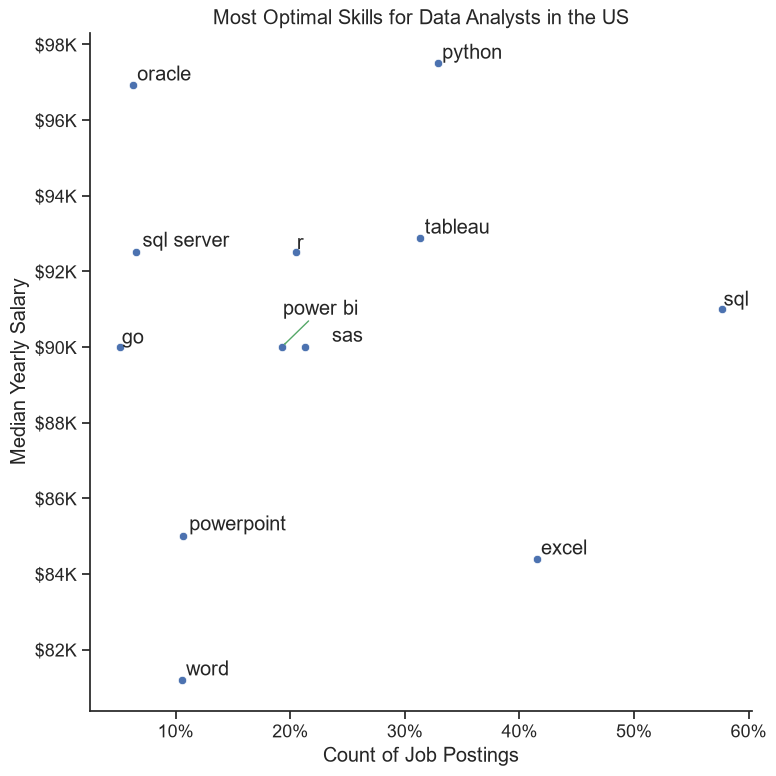

In [16]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(data=df_DA_skills_high_demand, x="skill_percent", y="median_salary", ax=ax)
sns.despine()

texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
	texts.append(
		plt.text(df_DA_skills_high_demand["skill_percent"].iloc[i], df_DA_skills_high_demand["median_salary"].iloc[i], txt)
	)

adjust_text(texts, arrowprops={"arrowstyle": "->", "color": "g", "lw": 1})

ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${int(y / 1000)}K"))

plt.xlabel("Count of Job Postings")
plt.ylabel("Median Yearly Salary")
plt.title("Most Optimal Skills for Data Analysts in the US")
plt.tight_layout()
plt.show()

## Classify skills by technology type

As an additional view, consolidate the dataset's technology-to-skill mappings. Duplicate mappings and missing records are removed before the categories are combined.

In [ ]:
df_technology = df['job_type_skills'].copy()
df_technology = df_technology.drop_duplicates()
df_technology = df_technology.dropna()

# combine all dictionaries into one
technology_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row)
    for key, value in row_dict.items():
        if key in technology_dict:
            technology_dict[key] += value
        else:
            technology_dict[key] = value

for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['spss',
  'sap',
  'esquisse',
  'sheets',
  'datarobot',
  'visio',
  'sharepoint',
  'tableau',
  'qlik',
  'power bi',
  'word',
  'ssrs',
  'spreadsheet',
  'alteryx',
  'excel',
  'splunk',
  'microstrategy',
  'sas',
  'ms access',
  'ssis',
  'nuix',
  'powerpoint',
  'outlook',
  'msaccess',
  'cognos',
  'dax',
  'looker',
  'powerbi'],
 'programming': ['sql',
  'julia',
  'visual basic',
  'php',
  'powershell',
  'perl',
  'go',
  'css',
  'scala',
  'r',
  'cobol',
  'elixir',
  'shell',
  'clojure',
  'kotlin',
  'haskell',
  'swift',
  'c',
  'crystal',
  'golang',
  'visualbasic',
  'vb.net',
  'python',
  'no-sql',
  'fortran',
  'mongo',
  'c++',
  'vba',
  'groovy',
  'ruby',
  'erlang',
  'ocaml',
  'pascal',
  'mongodb',
  'bash',
  'apl',
  'sass',
  'delphi',
  'sas',
  'typescript',
  'c#',
  'matlab',
  'assembly',
  'rust',
  'lisp',
  'dart',
  'objective-c',
  'f#',
  'solidity',
  'html',
  'nosql',
  'lua',
  't-sql',
  'java',
  'javascr

## Reshape the technology mapping

Convert the combined mapping into a table and explode each category's skill list so every technology-skill pair occupies one row.

In [19]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=["technology", "skills"])
df_technology = df_technology.explode("skills")

df_technology

,technology,skills
0,analyst_tools,spss
0,analyst_tools,sap
0,analyst_tools,esquisse
0,analyst_tools,sheets
0,analyst_tools,datarobot
...,...,...
9,sync,zoom
9,sync,google chat
9,sync,slack
9,sync,symphony


## Attach categories to high-demand skills

Merge the filtered skill metrics with the technology mapping, keeping skills that have a matching category.

In [24]:
df_plot = df_DA_skills_high_demand.merge(df_technology, left_on="job_skills", right_on="skills")
df_plot

,skill_count,median_salary,skill_percent,technology,skills
0,2508,91000.00,57.655172,programming,sql
1,1808,84392.00,41.563218,analyst_tools,excel
2,1431,97500.00,32.896552,programming,python
3,1364,92875.00,31.356322,analyst_tools,tableau
4,926,90000.00,21.287356,analyst_tools,sas
5,926,90000.00,21.287356,programming,sas
6,893,92500.00,20.528736,programming,r
7,838,90000.00,19.264368,analyst_tools,power bi
8,462,85000.00,10.620690,analyst_tools,powerpoint
9,461,81194.75,10.597701,analyst_tools,word


## Compare skills by technology category

Replot the demand-and-salary relationship with color indicating technology type. The horizontal measure remains the percentage of salary-reported Data Analyst postings that mention each skill.

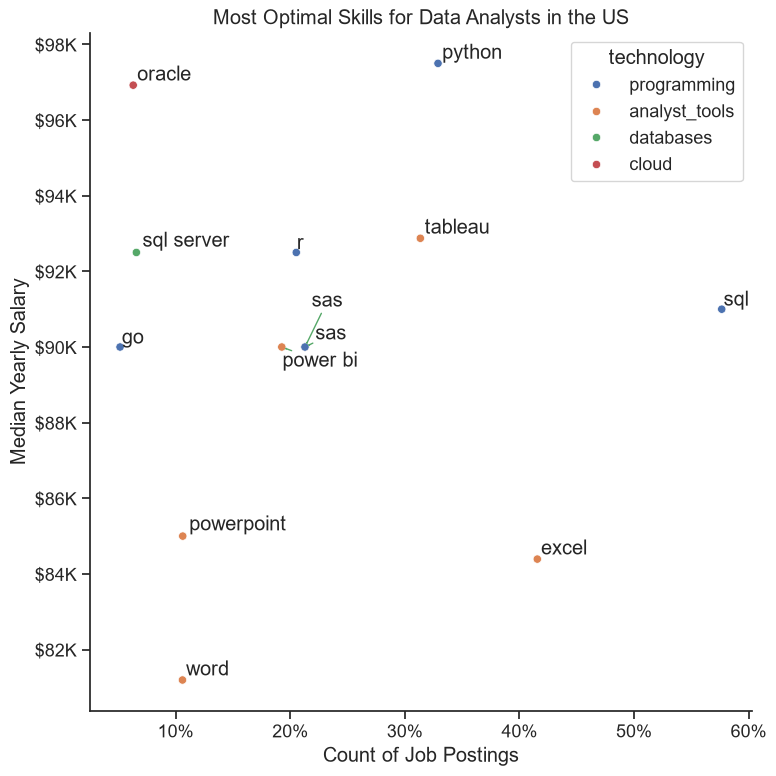

In [27]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(data=df_plot, x="skill_percent", y="median_salary", ax=ax, hue="technology")
sns.despine()

texts = []
for i, txt in enumerate(df_plot["skills"]):
	texts.append(
		plt.text(df_plot["skill_percent"].iloc[i], df_plot["median_salary"].iloc[i], txt)
	)

adjust_text(texts, arrowprops={"arrowstyle": "->", "color": "g", "lw": 1})

ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${int(y / 1000)}K"))

plt.xlabel("Count of Job Postings")
plt.ylabel("Median Yearly Salary")
plt.title("Most Optimal Skills for Data Analysts in the US")
plt.tight_layout()
plt.show()